# Phi-3 · Aprendizaje por retroalimentación humana

DistilBERT estima cuál de dos respuestas para la misma solicitud se ajusta mejor a las preferencias de HH-RLHF. A partir del adaptador SFT de Phi-3, PPO optimiza esa señal con una penalización por alejarse de la política de referencia. El cuaderno de [evaluación](evaluacion.ipynb) compara la política resultante con zero-shot, few-shot y SFT.

Usa el kernel **Tarea 3 (GPU)** o **rocm (3.14.10)** en VS Code. El [entrenamiento SFT](entrenamiento.ipynb) debe haber guardado el adaptador en `salidas/sft_lr5e5/`.

In [1]:
from pathlib import Path
import sys

folder = Path.cwd() if Path("comun.py").is_file() else Path.cwd() / "tarea3"
if not (folder / "comun.py").is_file():
    raise FileNotFoundError("Abre el cuaderno desde la carpeta tarea3 o la raiz del repositorio.")
sys.path.insert(0, str(folder))

from comun import preparar_notebook

preparar_notebook()

Python 3.14.10 · entorno rocm


In [2]:
import os

from IPython.display import Markdown, display

from comun import OUT, SFT_DIR
from rlhf import (
    PPO_DIR, REWARD_DIR, clear_gpu, confirm_reward, output_name,
    read_json, read_partitions, train_ppo, train_reward,
)

PILOTO = os.getenv("TAREA3_PILOTO") == "1"
if not (OUT / SFT_DIR / "adapter_model.safetensors").is_file():
    raise FileNotFoundError("Ejecuta el entrenamiento SFT completo antes de iniciar RLHF.")

particiones, huellas = read_partitions(PILOTO)
print("Modo:", "piloto" if PILOTO else "final")
for nombre in ("sft", "recompensa_train", "recompensa_val", "ppo"):
    print(f"{nombre}: {len(particiones[nombre])} filas")

Modo: final
sft: 512 filas
recompensa_train: 1024 filas
recompensa_val: 128 filas
ppo: 128 filas


## Modelo de recompensa

Para cada solicitud se puntúan por separado la respuesta preferida y la rechazada. La pérdida es $-\log\sigma(r_\mathrm{preferida}-r_\mathrm{rechazada})$. El máximo es de 512 tokens por par solicitud–respuesta y se reservan hasta 128 para la solicitud.

DistilBERT se reinicia desde el checkpoint preentrenado y se entrena durante seis épocas completas. La tasa máxima es `1e-5`, con calentamiento durante el primer 10 % de los pasos y decaimiento lineal. En validación, la pérdida de `harmless-base` pesa dos tercios y la de `helpful-base` pesa un tercio. Se elige la época con menor pérdida ponderada y se desempata por precisión en `harmless-base` y por la época más temprana.

La confirmación compara los modelos en 512 pares nuevos de cada fuente, después de fijar el checkpoint. La normalización para PPO usa los puntajes de entrenamiento del checkpoint seleccionado.

In [3]:
import torch

torch.set_num_threads(min(torch.get_num_threads(), 8))
ruta_referencia = OUT / output_name(REWARD_DIR, PILOTO)
if not PILOTO or ruta_referencia.is_dir():
    _, referencia = train_reward(particiones, huellas, PILOTO)
else:
    referencia = None
clear_gpu()

ruta_recompensa, recompensa = train_reward(particiones, huellas, PILOTO, six_epochs=True)
clear_gpu()
print(ruta_recompensa.relative_to(OUT.parent))

Reutilizando recompensa en tarea3\salidas\recompensa_distilbert
Reutilizando recompensa en tarea3\salidas\recompensa_distilbert_6e
salidas\recompensa_distilbert_6e


Recortes de la candidata: {'train': {'pares_prompt_truncado': 2, 'preferidas_truncadas': 1, 'rechazadas_truncadas': 0}, 'val': {'pares_prompt_truncado': 0, 'preferidas_truncadas': 0, 'rechazadas_truncadas': 0}}


| Corrida | Época elegida | Fuente | Pares | Precisión · IC 95 % | Pérdida |
|---|---:|---|---:|---:|---:|
| Referencia | 1 | Total | 128 | 62.5% [53.9%, 70.4%] | 0.6852 |
| Referencia | 1 | helpful-base | 64 | 73.4% [61.5%, 82.7%] | 0.6623 |
| Referencia | 1 | harmless-base | 64 | 51.6% [39.6%, 63.4%] | 0.7081 |
| Candidata | 4 | Total | 128 | 58.6% [49.9%, 66.8%] | 0.6677 |
| Candidata | 4 | helpful-base | 64 | 59.4% [47.1%, 70.5%] | 0.6465 |
| Candidata | 4 | harmless-base | 64 | 57.8% [45.6%, 69.1%] | 0.6890 |

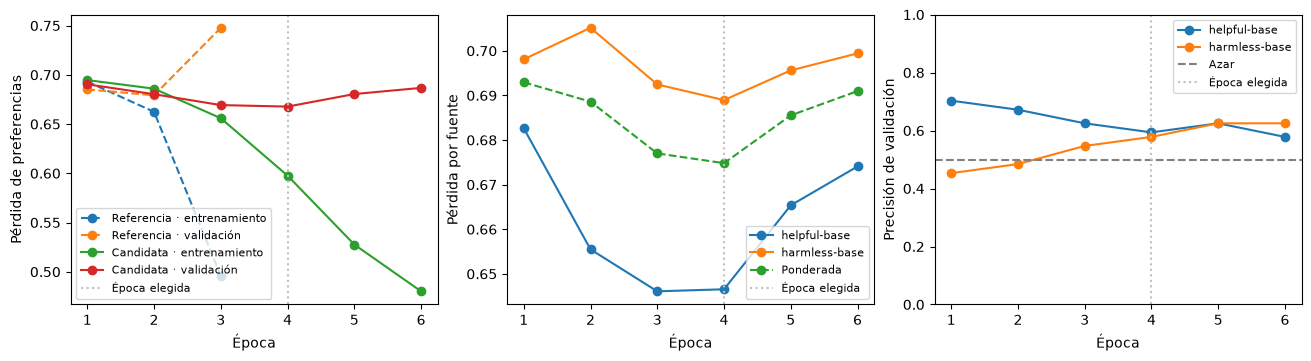

In [4]:
import matplotlib.pyplot as plt
from revision import wilson

filas = [
    "| Corrida | Época elegida | Fuente | Pares | Precisión · IC 95 % | Pérdida |",
    "|---|---:|---|---:|---:|---:|",
]
corridas = [("Referencia", referencia), ("Candidata", recompensa)]
for nombre, corrida in corridas:
    if corrida is None:
        continue
    validacion = corrida["validacion"]
    por_fuente = {"Total": validacion, **validacion["por_fuente"]}
    for fuente in por_fuente:
        metricas = por_fuente[fuente]
        lo, hi = wilson(round(metricas["accuracy"] * metricas["pares"]), metricas["pares"])
        filas.append(f"| {nombre} | {corrida['mejor_epoca']} | {fuente} | {metricas['pares']} | "
                     f"{metricas['accuracy']:.1%} [{lo:.1%}, {hi:.1%}] | {metricas['loss']:.4f} |")
display(Markdown("\n".join(filas)))
print("Recortes de la candidata:", recompensa["recortes"])

historial = recompensa["historial"]
epocas = [fila["epoca"] for fila in historial]
fig, (ax_loss, ax_fuente, ax_acc) = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained")
for corrida, estilo in ((referencia, "o--"), (recompensa, "o-")):
    if corrida is None:
        continue
    serie = corrida["historial"]
    eje = [fila["epoca"] for fila in serie]
    nombre = "Referencia" if corrida is referencia else "Candidata"
    ax_loss.plot(eje, [fila["loss_train"] for fila in serie], estilo, label=f"{nombre} · entrenamiento")
    ax_loss.plot(eje, [fila["loss"] for fila in serie], estilo, label=f"{nombre} · validación")
for fuente in ("helpful-base", "harmless-base"):
    valores = [fila["por_fuente"][fuente] for fila in historial]
    ax_fuente.plot(epocas, [fila["loss"] for fila in valores], "o-", label=fuente)
    ax_acc.plot(epocas, [fila["accuracy"] for fila in valores], "o-", label=fuente)
ax_fuente.plot(epocas, [fila["loss_ponderada"] for fila in historial], "o--", label="Ponderada")
ax_acc.axhline(.5, color="0.5", linestyle="--", label="Azar")
for ax, ylabel in zip((ax_loss, ax_fuente, ax_acc),
                      ("Pérdida de preferencias", "Pérdida por fuente", "Precisión de validación"), strict=True):
    ax.axvline(recompensa["mejor_epoca"], color="0.75", linestyle=":", label="Época elegida")
    ax.set(xlabel="Época", ylabel=ylabel, xticks=epocas)
    ax.legend(fontsize=8)
ax_acc.set_ylim(0, 1)
plt.show()

In [5]:
confirmacion = None
if PILOTO:
    print("Piloto: la confirmación se ejecuta sobre la corrida de seis épocas.")
else:
    confirmacion = confirm_reward(particiones, huellas, ruta_recompensa, recompensa)
    clear_gpu()
    filas = [
        "| Fuente | Pares | Precisión referencia · IC 95 % | Precisión candidata · IC 95 % | Cambio | Pérdida referencia | Pérdida candidata |",
        "|---|---:|---:|---:|---:|---:|---:|",
    ]
    for fuente in confirmacion["por_fuente"]:
        antes = confirmacion["referencia"]["por_fuente"][fuente]
        despues = confirmacion["candidata"]["por_fuente"][fuente]
        pares = confirmacion["por_fuente"][fuente]
        lo_a, hi_a = wilson(round(antes["accuracy"] * pares["pares"]), pares["pares"])
        lo_b, hi_b = wilson(round(despues["accuracy"] * pares["pares"]), pares["pares"])
        filas.append(f"| {fuente} | {pares['pares']} | {antes['accuracy']:.2%} [{lo_a:.1%}, {hi_a:.1%}] | {despues['accuracy']:.2%} [{lo_b:.1%}, {hi_b:.1%}] | "
                     f"{pares['delta_accuracy'] * 100:+.2f} pp | {antes['loss']:.4f} | {despues['loss']:.4f} |")
    display(Markdown("\n".join(filas)))
    harmless = confirmacion["por_fuente"]["harmless-base"]
    print(f"McNemar unilateral en harmless-base: p={harmless['p_mcnemar_unilateral']:.4g} "
          f"({harmless['ganadas']} mejoras y {harmless['perdidas']} retrocesos).")
    for criterio, texto in (
        ("harmless_mejora_minima", "Mejora de harmless-base de al menos 5 pp"),
        ("harmless_mcnemar", "McNemar unilateral con p ≤ 0,05"),
        ("harmless_perdida", "Pérdida de harmless-base igual o menor"),
        ("helpful_tolerancia", "Caída de helpful-base de hasta 5 pp"),
    ):
        print(f"{texto}: {'cumple' if confirmacion['criterios'][criterio] else 'no cumple'}.")
    print("Decisión:", "entrenar PPO con la candidata" if confirmacion["aprobada"]
          else "conservar PPO de referencia.")

McNemar unilateral en harmless-base: p=9.153e-05 (120 mejoras y 68 retrocesos).
Mejora de harmless-base de al menos 5 pp: cumple.
McNemar unilateral con p ≤ 0,05: cumple.
Pérdida de harmless-base igual o menor: cumple.
Caída de helpful-base de hasta 5 pp: cumple.
Decisión: entrenar PPO con la candidata


| Fuente | Pares | Precisión referencia · IC 95 % | Precisión candidata · IC 95 % | Cambio | Pérdida referencia | Pérdida candidata |
|---|---:|---:|---:|---:|---:|---:|
| helpful-base | 512 | 64.84% [60.6%, 68.9%] | 60.35% [56.1%, 64.5%] | -4.49 pp | 0.6689 | 0.6528 |
| harmless-base | 512 | 46.48% [42.2%, 50.8%] | 56.64% [52.3%, 60.9%] | +10.16 pp | 0.7014 | 0.6819 |

## Optimización PPO

La política y la referencia comienzan con los mismos pesos SFT y comparten Phi-3 cuantizado. Se muestrea una respuesta por solicitud. PPO aplica la recompensa normalizada al último token y descuenta, en cada acción, la diferencia entre el logaritmo de la probabilidad de la política anterior y el de la referencia. Se usa GAE con $\gamma=1$ y $\lambda=0.95$, con valor futuro cero al terminar por EOS o por el límite. La pérdida de política y la de valor usan clipping de 0,2.

Cada lote mezcla dos solicitudes de cada fuente y se actualiza durante dos épocas. La corrida final usa 128 solicitudes y un máximo de 64 tokens por respuesta de entrenamiento. PPO se ejecuta cuando la confirmación independiente cumple los cuatro criterios. Si se interrumpe una corrida, vuelve a ejecutar la celda para retomar desde el último checkpoint compatible.

In [6]:
reporte_ppo = None
if confirmacion and confirmacion["aprobada"]:
    ruta_ppo, reporte_ppo = train_ppo(particiones, huellas, ruta_recompensa, recompensa, PILOTO)
    clear_gpu()
    print(f"Adaptador PPO de la candidata: {ruta_ppo.relative_to(OUT.parent)}")
elif not PILOTO:
    referencia_ppo = OUT / PPO_DIR / "reporte.json"
    if referencia_ppo.is_file():
        reporte_ppo = read_json(referencia_ppo)
        print(f"PPO vigente (referencia): {referencia_ppo.parent.relative_to(OUT.parent)}")

Reutilizando adaptador PPO completo en tarea3\salidas\ppo_lr3e6_6e
Adaptador PPO de la candidata: salidas\ppo_lr3e6_6e


Lotes: 32 · referencia intacta: True


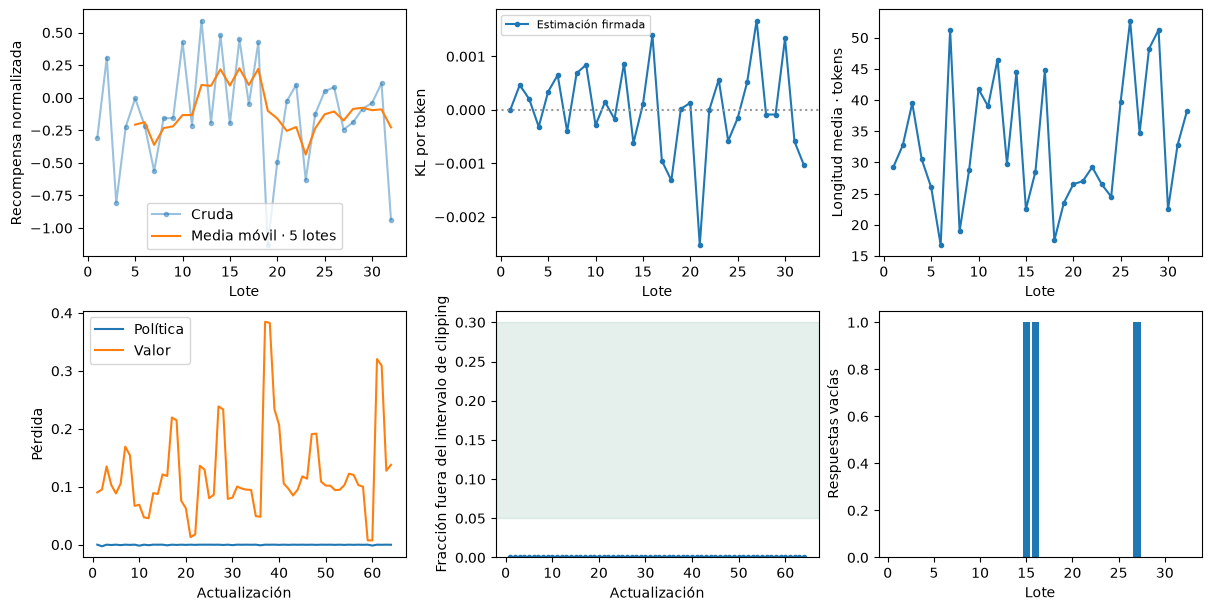

In [7]:
from informes import figura_ppo

if reporte_ppo is not None:
    fig = figura_ppo(reporte_ppo["historial"])
    fig.savefig(OUT / "ppo_6e_diagnostico.png", dpi=160)
    plt.show()
    print(f"Lotes: {len(reporte_ppo['historial'])} · referencia intacta: {reporte_ppo['referencia_intacta']}")

## Objetivos de entrenamiento

**Preferencias de recompensa.** DistilBERT puntúa las respuestas preferida y rechazada para la misma solicitud. Se minimiza $-\log\sigma(r_\mathrm{preferida}-r_\mathrm{rechazada})$.

**Recompensa para PPO.** Se aplica $-\beta(\log\pi_\mathrm{anterior}(a_t)-\log\pi_\mathrm{SFT}(a_t))$ en cada acción y se suma al último token el puntaje escalar normalizado, recortado a $[-5,5]$.

**Objetivo PPO.** Con $\rho_t=\pi_\theta(a_t)/\pi_\mathrm{anterior}(a_t)$ se maximiza $\min(\rho_t A_t,\operatorname{clip}(\rho_t,1-\epsilon,1+\epsilon)A_t)$, con $\epsilon=0{,}2$. El entrenamiento también ajusta el valor con su pérdida recortada. La columna de clipping mide cuántos ratios quedaron fuera de ese intervalo. La banda de diagnóstico para esa fracción es 5–30 %.

## Lectura de resultados

La precisión indica qué tan seguido el modelo de recompensa ordena correctamente los pares de validación. Las curvas PPO describen la señal que optimizó la política durante el muestreo. En la [evaluación comparativa](evaluacion.ipynb), Toxic-BERT puntúa las respuestas y la revisión humana mide seguridad, utilidad y rechazos innecesarios con los mismos prompts para las configuraciones de la comparación final.

Referencias metodológicas. [HH-RLHF](https://huggingface.co/datasets/Anthropic/hh-rlhf), [PPO](https://arxiv.org/abs/1707.06347) y [GAE](https://arxiv.org/abs/1506.02438).

## Experimentos PPO con más datos

Cada experimento toma 512 prompts balanceados, ocho rollouts por lote y cuatro actualizaciones por lote. Se prueban tasas iniciales de política `1e-5` y `3e-5` en artefactos separados, con tasa del crítico `1e-4` y β inicial `0,05`. Los microlotes acumulan el gradiente normalizado por tokens antes de actualizar. Una segunda pasada es opcional. El comando y los controles de memoria están en el README.

Se generan hasta 64 tokens en PPO y hasta 256 en evaluación. Esta diferencia permite comparar el protocolo histórico y limita lo que se puede inferir sobre respuestas largas. Si el KL sube por encima de 0,05–0,10 o se observa degeneración, probar β = 0,1 en otra corrida. Si el KL sigue cerca de cero tras completar el plan, probar β = 0,02. El intervalo de clipping y los umbrales son diagnósticos operativos. La repetición se marca si al menos el 35 % de los n-gramas de cuatro palabras se repite en una respuesta de doce palabras o más.

phi3_ppo_6e · KL en 0,005–0,05: no, clipping en 5–30 %: no, recompensa final mayor: sí, al menos 20 % de respuestas distintas: no, sin vacías ni repetición marcada: sí
phi3_ppo_lr1e5_512_p1_m8_g8_kl0.05 · KL en 0,005–0,05: sí, clipping en 5–30 %: no, recompensa final mayor: sí, al menos 20 % de respuestas distintas: sí, sin vacías ni repetición marcada: no
Piloto ppo_lr1e5_512_p1_m8_g8_kl0.05_piloto · 31.7 s · pico asignado 3.06 GiB
Piloto ppo_lr3e5_512_p1_m8_g8_kl0.05_piloto · 31.9 s · pico asignado 3.06 GiB


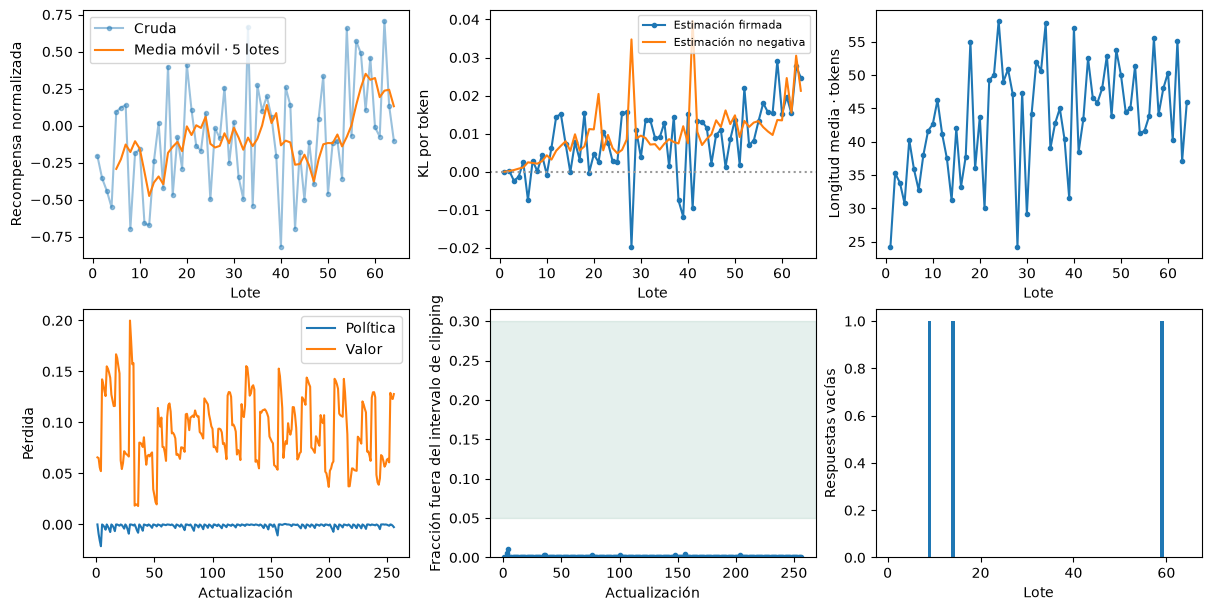

| Configuración | Lotes | Recompensa primeros 8 | Últimos 8 | KL por token | Clipping | Distintas de SFT | Vacías | Repetitivas | Veredicto |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---|
| PPO · 6 épocas | 32 | -0.2459 | -0.1566 | -0.0000 | 0.00% | 11.7% | 0 | 0 | Cumplimiento parcial |
| PPO · 1e-5 | 64 | -0.2373 | 0.2127 | 0.0099 | 0.01% | 66.7% | 0 | 2 | Cumplimiento parcial |

In [8]:
from IPython.display import Markdown, display
from informes import decimal, diagnostico_ppo, experimentos_ppo, nombre_config
from revision import leer_csv

base = OUT / "respuestas_256" / "final_6e"
if not (base / "phi3_sft.csv").exists():
    base = OUT / "respuestas_256" / "final"
candidatas = []
if reporte_ppo is not None:
    nombre = "phi3_ppo_6e" if (base / "phi3_ppo_6e.csv").exists() else "phi3_ppo"
    candidatas.append((nombre, reporte_ppo, base / f"{nombre}.csv"))
for artefacto, reporte in experimentos_ppo(OUT):
    nombre = f"phi3_{artefacto.name}"
    candidatas.append((nombre, reporte, base.with_name("ppo_experimentos") / f"{nombre}.csv"))
    fig = figura_ppo(reporte["historial"])
    fig.savefig(artefacto / "diagnostico.png", dpi=160)
    plt.show()

referencia_sft = leer_csv(base / "phi3_sft.csv") if (base / "phi3_sft.csv").exists() else []
tabla = ["| Configuración | Lotes | Recompensa primeros 8 | Últimos 8 | KL por token | Clipping | "
         "Distintas de SFT | Vacías | Repetitivas | Veredicto |",
         "|---|---:|---:|---:|---:|---:|---:|---:|---:|---|"]
for nombre, reporte, path in candidatas:
    respuestas = referencia_sft + leer_csv(path) if referencia_sft and path.exists() else []
    d = diagnostico_ppo(reporte, respuestas, nombre)
    diferencia = "—" if d["diferentes"] is None else f"{d['diferentes']:.1%}"
    vacias = d["vacias"] if respuestas else "—"
    repetidas = d["repetitivas"] if respuestas else "—"
    tabla.append(f"| {nombre_config(nombre)} | {len(reporte['historial'])} | {decimal(d['inicial'])} | "
                 f"{decimal(d['final'])} | {decimal(d['kl'])} | {d['clipping']:.2%} | "
                 f"{diferencia} | {vacias} | {repetidas} | {d['veredicto']} |")
    print(nombre, "·", ", ".join(f"{meta}: {'sí' if cumple else 'pendiente' if not respuestas else 'no'}"
                                for meta in d["metas"] for cumple in (d["metas"][meta],)))
display(Markdown("\n".join(tabla)))
for artefacto, reporte in experimentos_ppo(OUT, piloto=True):
    if reporte["config"]["microlote"] == 8:
        lote = reporte["historial"][0]
        print(f"Piloto {artefacto.name} · {lote['segundos']:.1f} s · "
              f"pico asignado {lote['pico_memoria_gib']:.2f} GiB")

## Límites del modelo de recompensa

La precisión de `harmless-base` queda relativamente cerca del azar y mide preferencias de pares. En la corrida de referencia de seis épocas, la pérdida de validación vuelve a aumentar después de la cuarta. La validación inicial tenía 64 pares por fuente, con intervalos anchos. DistilBERT reduce el costo de entrenamiento, y su capacidad para discriminar respuestas complejas puede ser menor que la de un clasificador más grande.

In [9]:
from informes import decimal
from rlhf import REWARD_EXPANDED_DIR

ruta = OUT / REWARD_EXPANDED_DIR
if (ruta / "reporte.json").is_file():
    ampliada = read_json(ruta / "reporte.json")
    print(f"Recompensa ampliada · {len(ampliada['historial'])} épocas · "
          f"época seleccionada {ampliada['mejor_epoca']}")
    for fuente in ampliada["validacion"]["por_fuente"]:
        m = ampliada["validacion"]["por_fuente"][fuente]
        lo, hi = wilson(round(m["accuracy"] * m["pares"]), m["pares"])
        print(f"{fuente}: {m['accuracy']:.1%} [{lo:.1%}, {hi:.1%}] · {m['pares']} pares")
    if (ruta / "confirmacion.json").is_file():
        control = read_json(ruta / "confirmacion.json")
        for fuente in control["por_fuente"]:
            a = control["referencia"]["por_fuente"][fuente]
            b = control["candidata"]["por_fuente"][fuente]
            ic_a = wilson(round(a["accuracy"] * a["pares"]), a["pares"])
            ic_b = wilson(round(b["accuracy"] * b["pares"]), b["pares"])
            print(f"Confirmación {fuente}: {a['accuracy']:.1%} [{ic_a[0]:.1%}, {ic_a[1]:.1%}] → "
                  f"{b['accuracy']:.1%} [{ic_b[0]:.1%}, {ic_b[1]:.1%}] · "
                  f"pérdida {decimal(a['loss'])} → {decimal(b['loss'])}")
        print("Cumple criterios de confirmación:", control["aprobada"])
else:
    print("Corrida ampliada pendiente. Se usa la recompensa de seis épocas confirmada para comparar ambas tasas PPO.")

Recompensa ampliada · 6 épocas · época seleccionada 3
helpful-base: 64.1% [58.0%, 69.7%] · 256 pares
harmless-base: 66.8% [60.8%, 72.3%] · 256 pares
Confirmación helpful-base: 60.4% [56.1%, 64.5%] → 65.6% [61.4%, 69.6%] · pérdida 0.6528 → 0.6576
Confirmación harmless-base: 56.6% [52.3%, 60.9%] → 61.9% [57.6%, 66.0%] · pérdida 0.6819 → 0.6616
Cumple criterios de confirmación: True
